# Wavenumber importance

> Which wavenumbers drive Kex predictions in the OSSL model on OSSL and on Fukushima spectra, and in the models trained on Fukushima, by integrated gradients, occlusion and ridge coefficients

In [ ]:
#| default_exp importance

In [ ]:
#| export
import copy
import numpy as np, pandas as pd, torch
from soilspecdl.all import BatchSNV, TensorSpectrum, predict
from ossl_fuku_transfer.data import shared_wns

/Users/franckalbinet/pro/dev/soilspec/ossl-fuku-transfer/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [ ]:
import matplotlib.pyplot as plt
from fastcore.test import *
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from soilspecdata.all import load_ossl
from soilspecdl.all import get_splitter, SpectralCNN
from ossl_fuku_transfer.data import *
from ossl_fuku_transfer.transfer import *
from ossl_fuku_transfer.inside import tracked_model

`12_wetchem` and `16_moisture` found that the OSSL Kex model fails on the Fukushima spectra, not on the soils, and that the Thermo spectra carry a shift of intensity from below 2000 cm⁻¹ to 2800–3700 cm⁻¹. The model also fails on the Bruker spectra of the same soils, which show little of that shift. This notebook asks which wavenumbers the models rely on, to see where OSSL and Fukushima differ in what matters for Kex.

Three methods, so that no single method decides: integrated gradients, occlusion, and ridge coefficients. The module part uses small random arrays, so it runs without the data. The sections from *Data and models* onwards read OSSL and the Fukushima data, and are marked `#| fukudata`.

## Methods

`integrated_gradients` attributes each prediction to the wavenumbers (Sundararajan et al. 2017). It works on the spectra after `BatchSNV`, as the model sees them, and integrates the gradient along the straight path from a flat spectrum of zeros to the spectrum, with `steps` points of the midpoint rule. The attributions of a spectrum sum to its prediction minus the prediction for the flat spectrum, up to the error of the integration:

In [ ]:
#| export
def integrated_gradients(
    model, # Trained `SpectralCNN`
    X, # Preprocessed spectra, one per row, as passed to `predict`
    steps=32, # Number of points on the path
    bs=128, # Batch size
)->np.ndarray: # One attribution per spectrum and wavenumber
    "Integrated gradients of the predictions of `model` for `X`, from a flat spectrum of zeros"
    m, snv, out = copy.deepcopy(model).cpu().eval(), BatchSNV(), []
    for i in range(0, len(X), bs):
        xs = torch.as_tensor(snv(TensorSpectrum(torch.tensor(X[i:i+bs], dtype=torch.float32).unsqueeze(1), wns=shared_wns))).float()
        g = torch.zeros_like(xs)
        for a in (torch.arange(steps) + 0.5) / steps:
            xi = (a * xs).requires_grad_(True)
            g += torch.autograd.grad(m(xi).sum(), xi)[0]
        out.append((xs * g / steps).squeeze(1).numpy())
    return np.concatenate(out)

In [ ]:
rng = np.random.default_rng(0)
X_syn = rng.normal(size=(6, len(shared_wns)))
m_syn = SpectralCNN().eval()
ig = integrated_gradients(m_syn, X_syn, steps=64)
xs = torch.as_tensor(BatchSNV()(TensorSpectrum(torch.tensor(X_syn, dtype=torch.float32).unsqueeze(1), wns=shared_wns))).float()
with torch.no_grad(): delta = (m_syn(xs) - m_syn(torch.zeros_like(xs))).numpy()
test_close(ig.sum(1), delta, eps=0.05 * np.abs(delta).max())

`occlusion` flattens one window of `width` wavenumbers at a time, setting the preprocessed spectra to zero there, and measures how much the mean squared error against `y` rises. It needs no gradients:

In [ ]:
#| export
def occlusion(
    model, # Trained `SpectralCNN`
    X, # Preprocessed spectra, one per row
    y, # Targets
    width=20, # Window width, in points
)->pd.DataFrame: # One row per window: its centre wavenumber and the rise in mean squared error
    "Rise in mean squared error of `model` when each window of `width` points of `X` is set to zero"
    base = ((predict(model, X, shared_wns) - y)**2).mean()
    rows = []
    for j in range(0, X.shape[1], width):
        Xo = X.copy()
        Xo[:, j:j+width] = 0
        rows.append({'wavenumber': shared_wns[j:j+width].mean(), 'rise in MSE': ((predict(model, Xo, shared_wns) - y)**2).mean() - base})
    return pd.DataFrame(rows)

In [ ]:
occ = occlusion(m_syn, X_syn, np.zeros(6), width=200)
test_eq(len(occ), int(np.ceil(len(shared_wns) / 200)))

`region_shares` gives the share of an importance profile that falls in each region:

In [ ]:
#| export
def region_shares(
    profile, # Non-negative importance per wavenumber
    wns, # Wavenumbers of `profile`
    regions:dict, # Name: (low, high) range in cm⁻¹
)->pd.Series: # One share per region
    "Share of the total of `profile` within each region"
    profile, wns = np.asarray(profile), np.asarray(wns)
    return pd.Series({k: profile[(wns >= lo) & (wns <= hi)].sum() / profile.sum() for k, (lo, hi) in regions.items()})

In [ ]:
test_close(region_shares(np.ones(4), np.arange(4), {'a': (0, 1), 'b': (2, 3)}).to_numpy(), [0.5, 0.5])

## Data and models

Kex as in `03_kex`. 2,000 OSSL validation spectra of the saved pretrained model, which it never trained on, and the Fukushima spectra. Three models: the saved OSSL model, and the fully fine-tuned and Fukushima-only models of `06_dynamics`:

In [ ]:
#| fukudata
om = load_ossl().mir(wmin=shared_wns[0], wmax=shared_wns[-1])
Xo, yo, _ = om.xy('k.ext_usda.a725_cmolc.kg')
yo = np.log1p(yo.ravel())
pipe = preprocessings()['snv_d1']
Xo_d = pipe.fit_transform(Xo)
va = get_splitter(0.9, 0.1, seed=42)(Xo_d, yo)[1]
vs = np.random.default_rng(0).choice(va, 2000, replace=False)
fuku = load_fuku()
fuku.source = fuku.source.assign(target=fuku.source['soil_ex_K2O'] / mg_k2o_per_cmolc)
Xf, yf, idf = fuku.xy('target')
yf = np.log1p(yf.ravel())
Xf_d = pipe.transform(Xf)
is_test = np.isin(idf, cs137_split()[1])
models = {'OSSL': load_pretrained('ossl_kex_snv_d1'), 'fully fine-tuned': tracked_model('dyn_fuku_kex_ft'), 'Fukushima only': tracked_model('dyn_fuku_kex_scratch')}
len(vs), int(is_test.sum())

(2000, 341)

Approximate band assignments for reading the profiles, in cm⁻¹. They are common assignments for soil MIR spectra, not fitted to these data:

In [ ]:
#| fukudata
bands = {3695: 'kaolinite OH', 3620: 'kaolinite, illite, smectite Al–OH', 3400: 'H-bonded O–H', 2920: 'aliphatic C–H', 2850: 'aliphatic C–H',
         2520: 'carbonate', 1630: 'H–O–H, amide, carboxylate', 1430: 'carbonate, carboxylate', 1100: 'Si–O', 1030: 'Si–O, clay',
         915: 'kaolinite Al–OH', 800: 'quartz', 780: 'quartz', 690: 'quartz'}
regions = {'650–1300': (650, 1300), '1300–2000': (1300, 2000), '2000–2800': (2000, 2800), '2800–3200': (2800, 3200),
           '3200–3600': (3200, 3600), '3600–3700': (3600, 3700), '3700–3998': (3700, 3998)}
def annotate(ax):
    for w in bands: ax.axvline(w, lw=0.4, c='tab:red', alpha=0.5)

## Integrated gradients

The mean absolute attribution per wavenumber, scaled to sum to 1, for the OSSL model on OSSL and on Fukushima spectra, and for the two Fukushima models on the Fukushima test spectra:

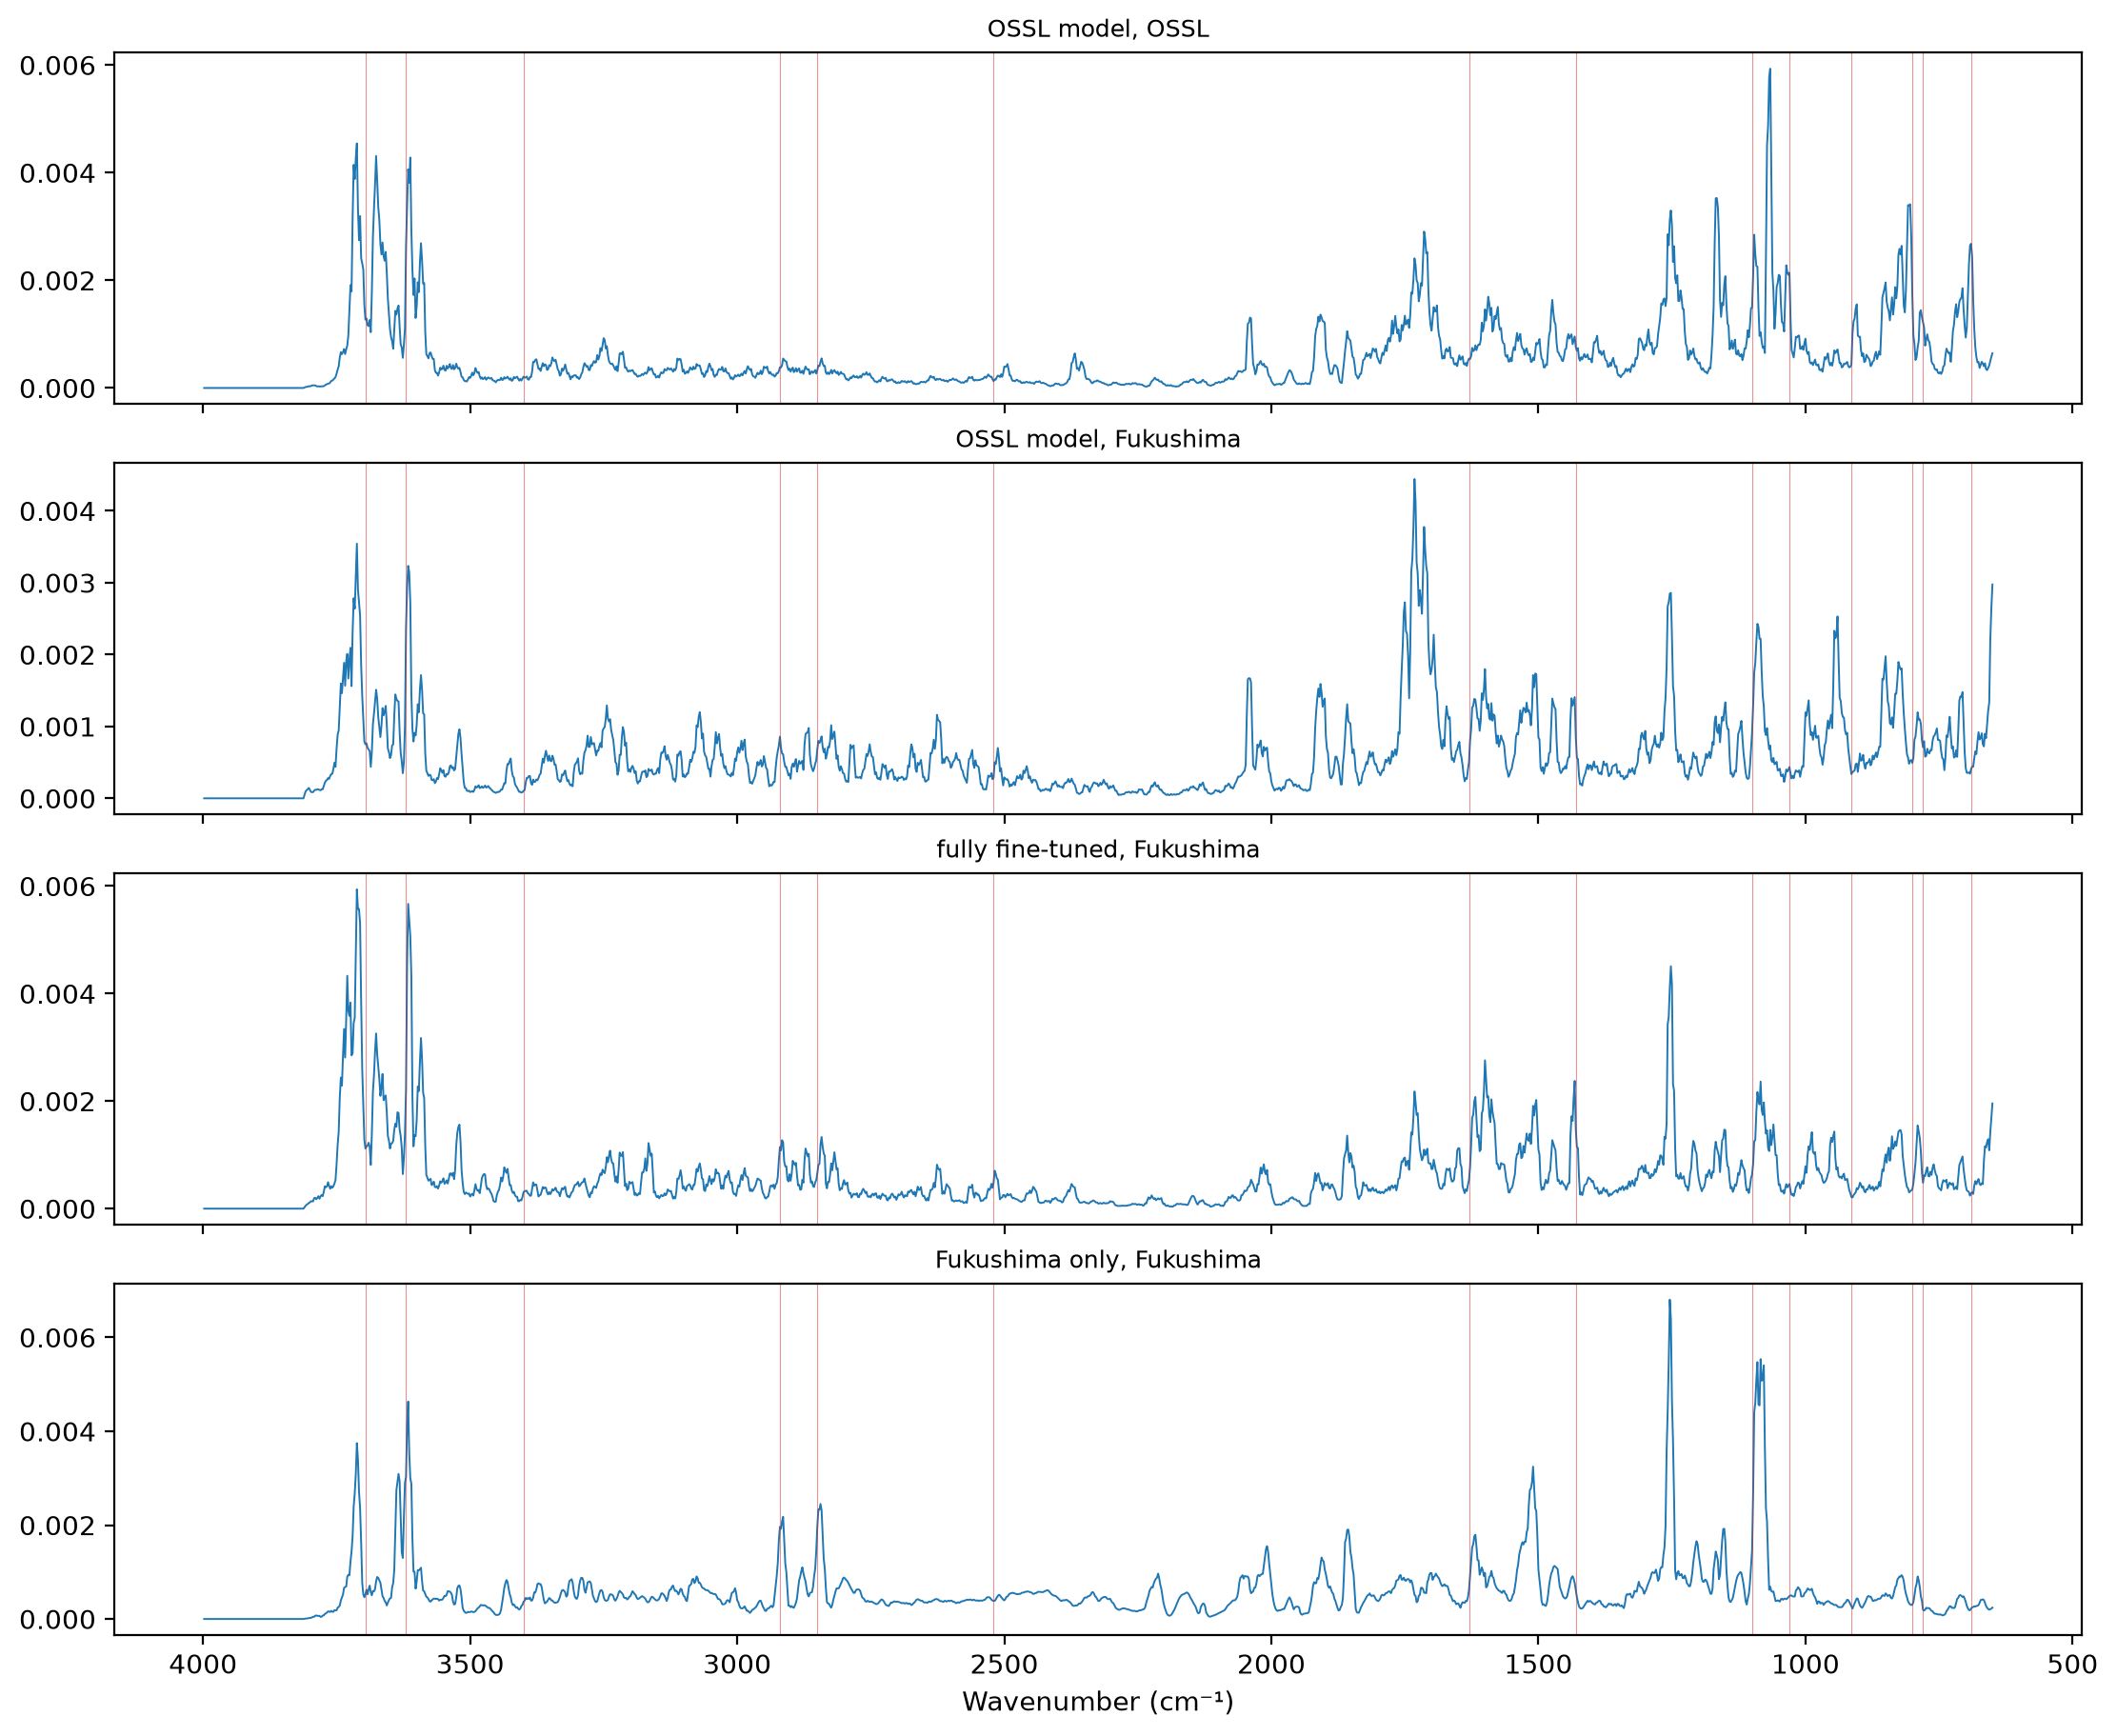

In [ ]:
#| fukudata
cases = {'OSSL model, OSSL': ('OSSL', Xo_d[vs]), 'OSSL model, Fukushima': ('OSSL', Xf_d),
         'fully fine-tuned, Fukushima': ('fully fine-tuned', Xf_d[is_test]), 'Fukushima only, Fukushima': ('Fukushima only', Xf_d[is_test])}
prof = {}
for k, (m, X) in cases.items():
    a = np.abs(integrated_gradients(models[m], X)).mean(0)
    prof[k] = a / a.sum()
prof = pd.DataFrame(prof, index=shared_wns)
fig, axs = plt.subplots(len(prof.columns), 1, figsize=(11, 9), sharex=True, layout='constrained')
for ax, k in zip(axs, prof):
    ax.plot(shared_wns, prof[k].rolling(5, center=True, min_periods=1).mean(), lw=0.7)
    ax.set_title(k, fontsize=9); annotate(ax)
axs[-1].invert_xaxis(); axs[-1].set_xlabel('Wavenumber (cm⁻¹)');

The correlation between the profiles, smoothed over 5 points, and the share of each profile per region:

In [ ]:
#| fukudata
sm = prof.rolling(5, center=True, min_periods=1).mean()
display(sm.corr().round(2))
pd.DataFrame({k: region_shares(prof[k], shared_wns, regions) for k in prof}).round(3)

,"OSSL model, OSSL","OSSL model, Fukushima","fully fine-tuned, Fukushima","Fukushima only, Fukushima"
"OSSL model, OSSL",1.00,0.66,0.69,0.48
"OSSL model, Fukushima",0.66,1.00,0.76,0.55
"fully fine-tuned, Fukushima",0.69,0.76,1.00,0.65
"Fukushima only, Fukushima",0.48,0.55,0.65,1.00


,"OSSL model, OSSL","OSSL model, Fukushima","fully fine-tuned, Fukushima","Fukushima only, Fukushima"
650–1300,0.379,0.283,0.260,0.272
1300–2000,0.258,0.292,0.239,0.236
2000–2800,0.068,0.121,0.090,0.176
2800–3200,0.063,0.104,0.110,0.123
3200–3600,0.083,0.089,0.110,0.093
3600–3700,0.102,0.057,0.101,0.068
3700–3998,0.051,0.056,0.095,0.037


## Occlusion

The rise in mean squared error of `log1p(Kex)` when each 40 cm⁻¹ window is flattened: the OSSL model on OSSL spectra and on the Fukushima test spectra, and the Fukushima-only model on the Fukushima test spectra:

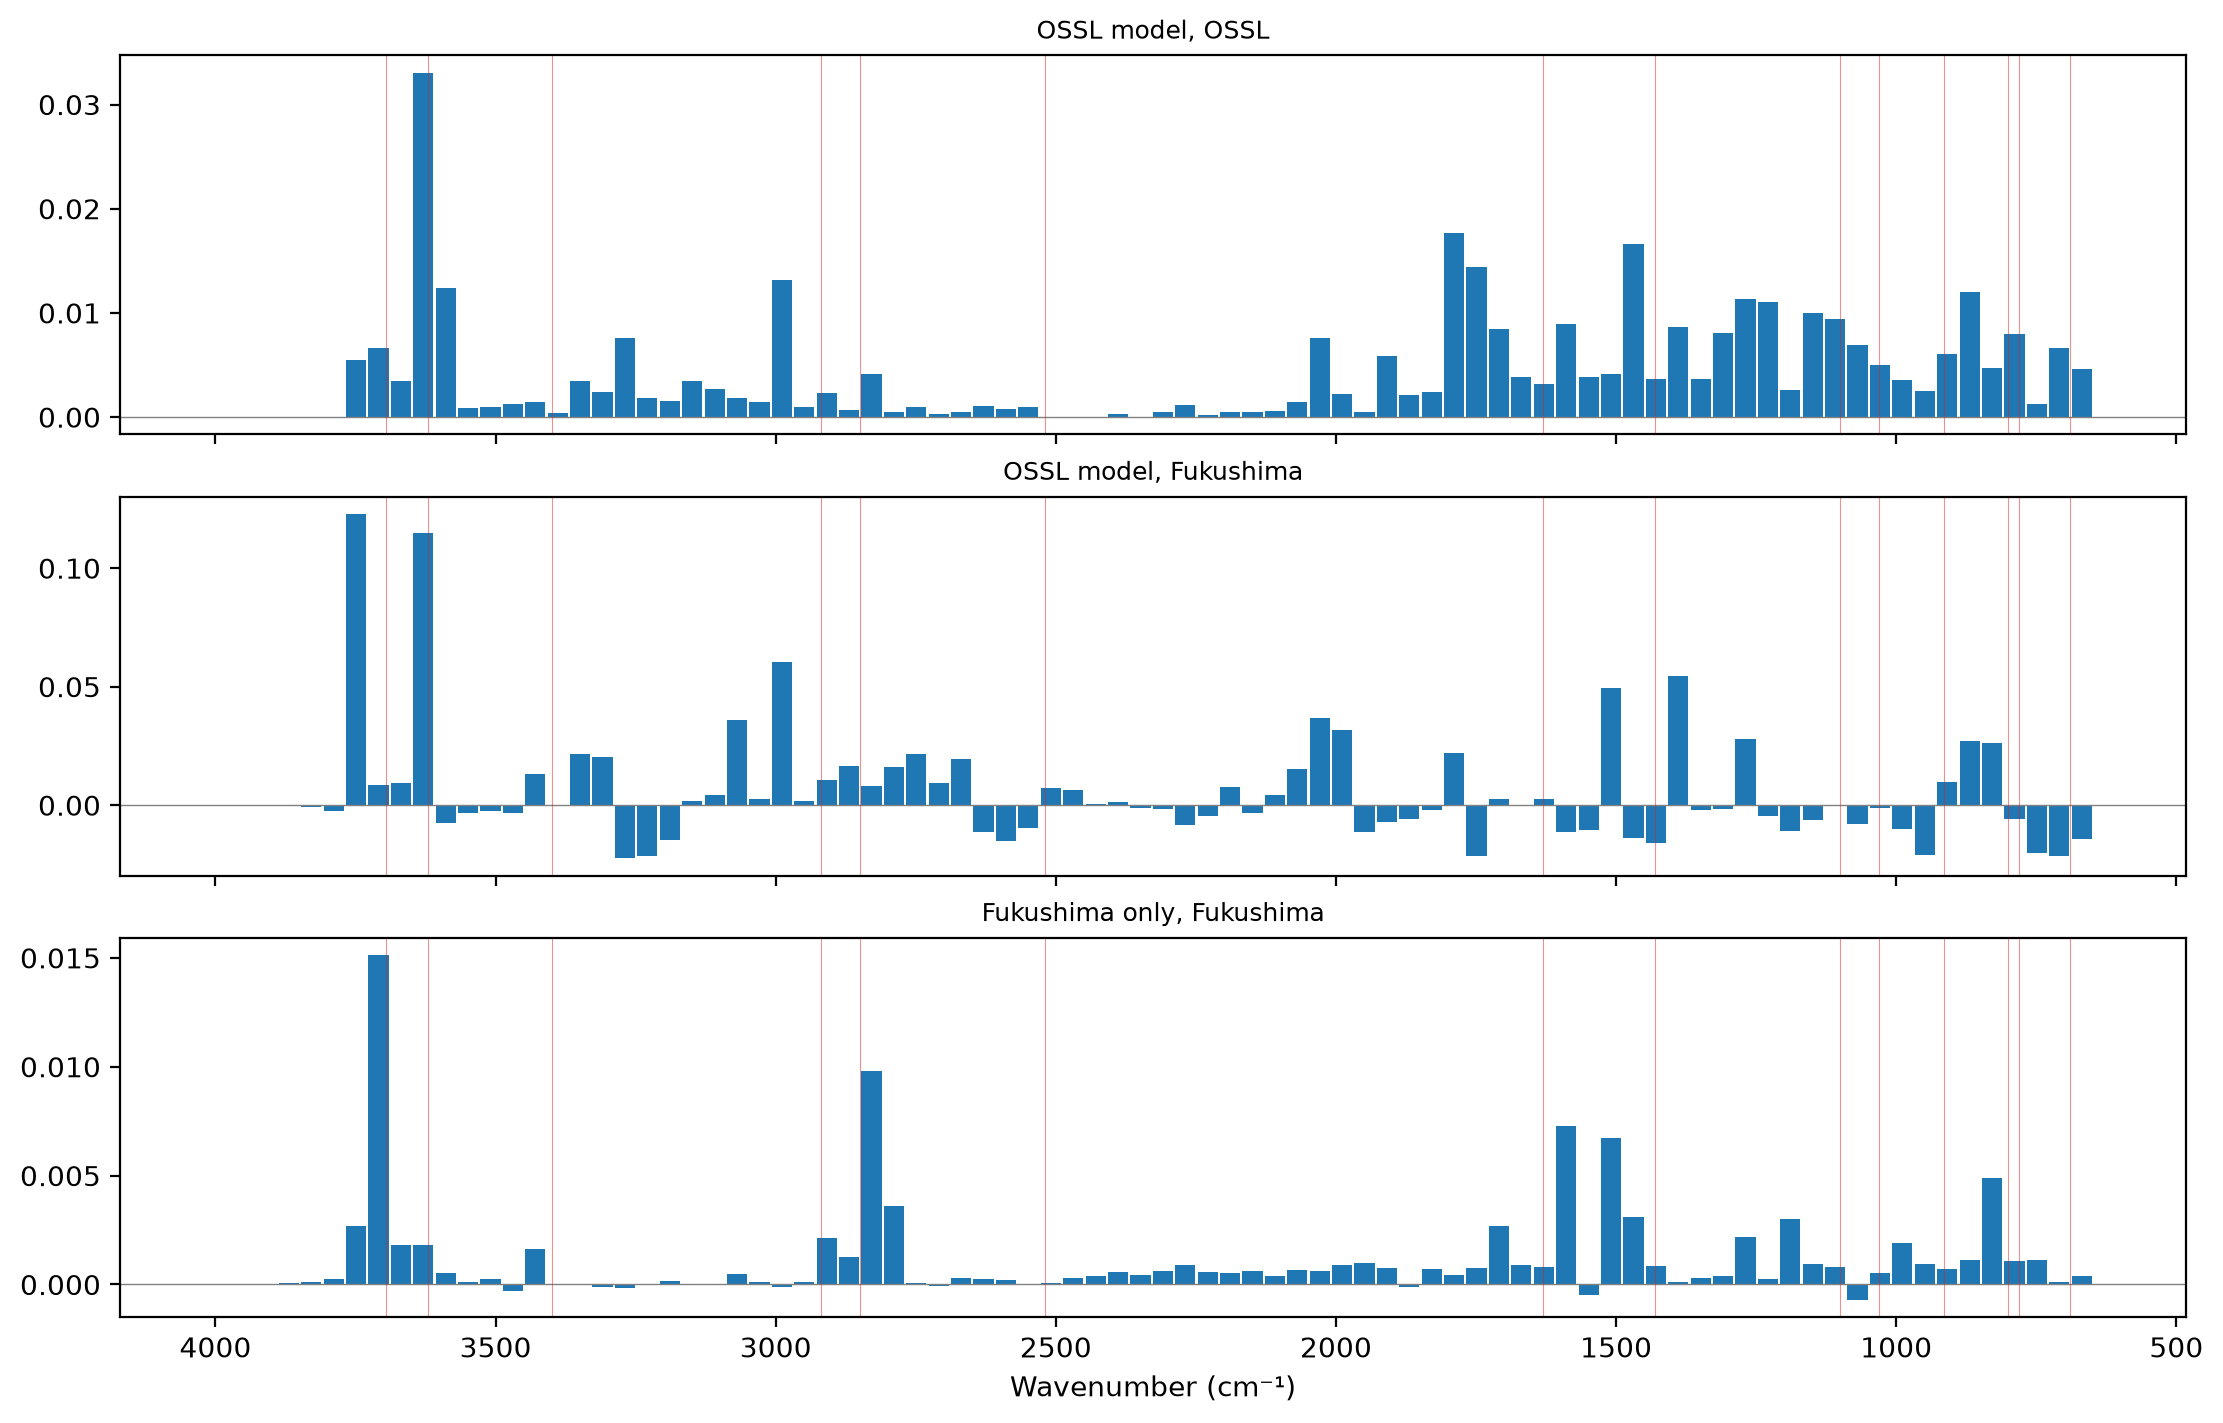

,"OSSL model, OSSL","OSSL model, Fukushima","Fukushima only, Fukushima"
1,3629.0,3749.0,3709.0
2,1789.0,3629.0,2829.0
3,1469.0,2989.0,1589.0
4,1749.0,1389.0,1509.0
5,2989.0,1509.0,829.0


In [ ]:
#| fukudata
occ = {'OSSL model, OSSL': occlusion(models['OSSL'], Xo_d[vs], yo[vs]),
       'OSSL model, Fukushima': occlusion(models['OSSL'], Xf_d[is_test], yf[is_test]),
       'Fukushima only, Fukushima': occlusion(models['Fukushima only'], Xf_d[is_test], yf[is_test])}
fig, axs = plt.subplots(len(occ), 1, figsize=(11, 7), sharex=True, layout='constrained')
for ax, (k, d) in zip(axs, occ.items()):
    ax.bar(d.wavenumber, d['rise in MSE'], width=36)
    ax.axhline(0, lw=0.5, c='grey'); ax.set_title(k, fontsize=9); annotate(ax)
axs[-1].invert_xaxis(); axs[-1].set_xlabel('Wavenumber (cm⁻¹)')
pd.DataFrame({k: d.nlargest(5, 'rise in MSE').wavenumber.round(0).to_numpy() for k, d in occ.items()}, index=range(1, 6))

## Ridge coefficients

The absolute coefficients of ridge regressions on the standardised spectra, scaled to sum to 1: one trained on 20,000 OSSL spectra, one on the Fukushima training samples. Their correlation with each other and with the integrated-gradient profiles, all smoothed over 5 points:

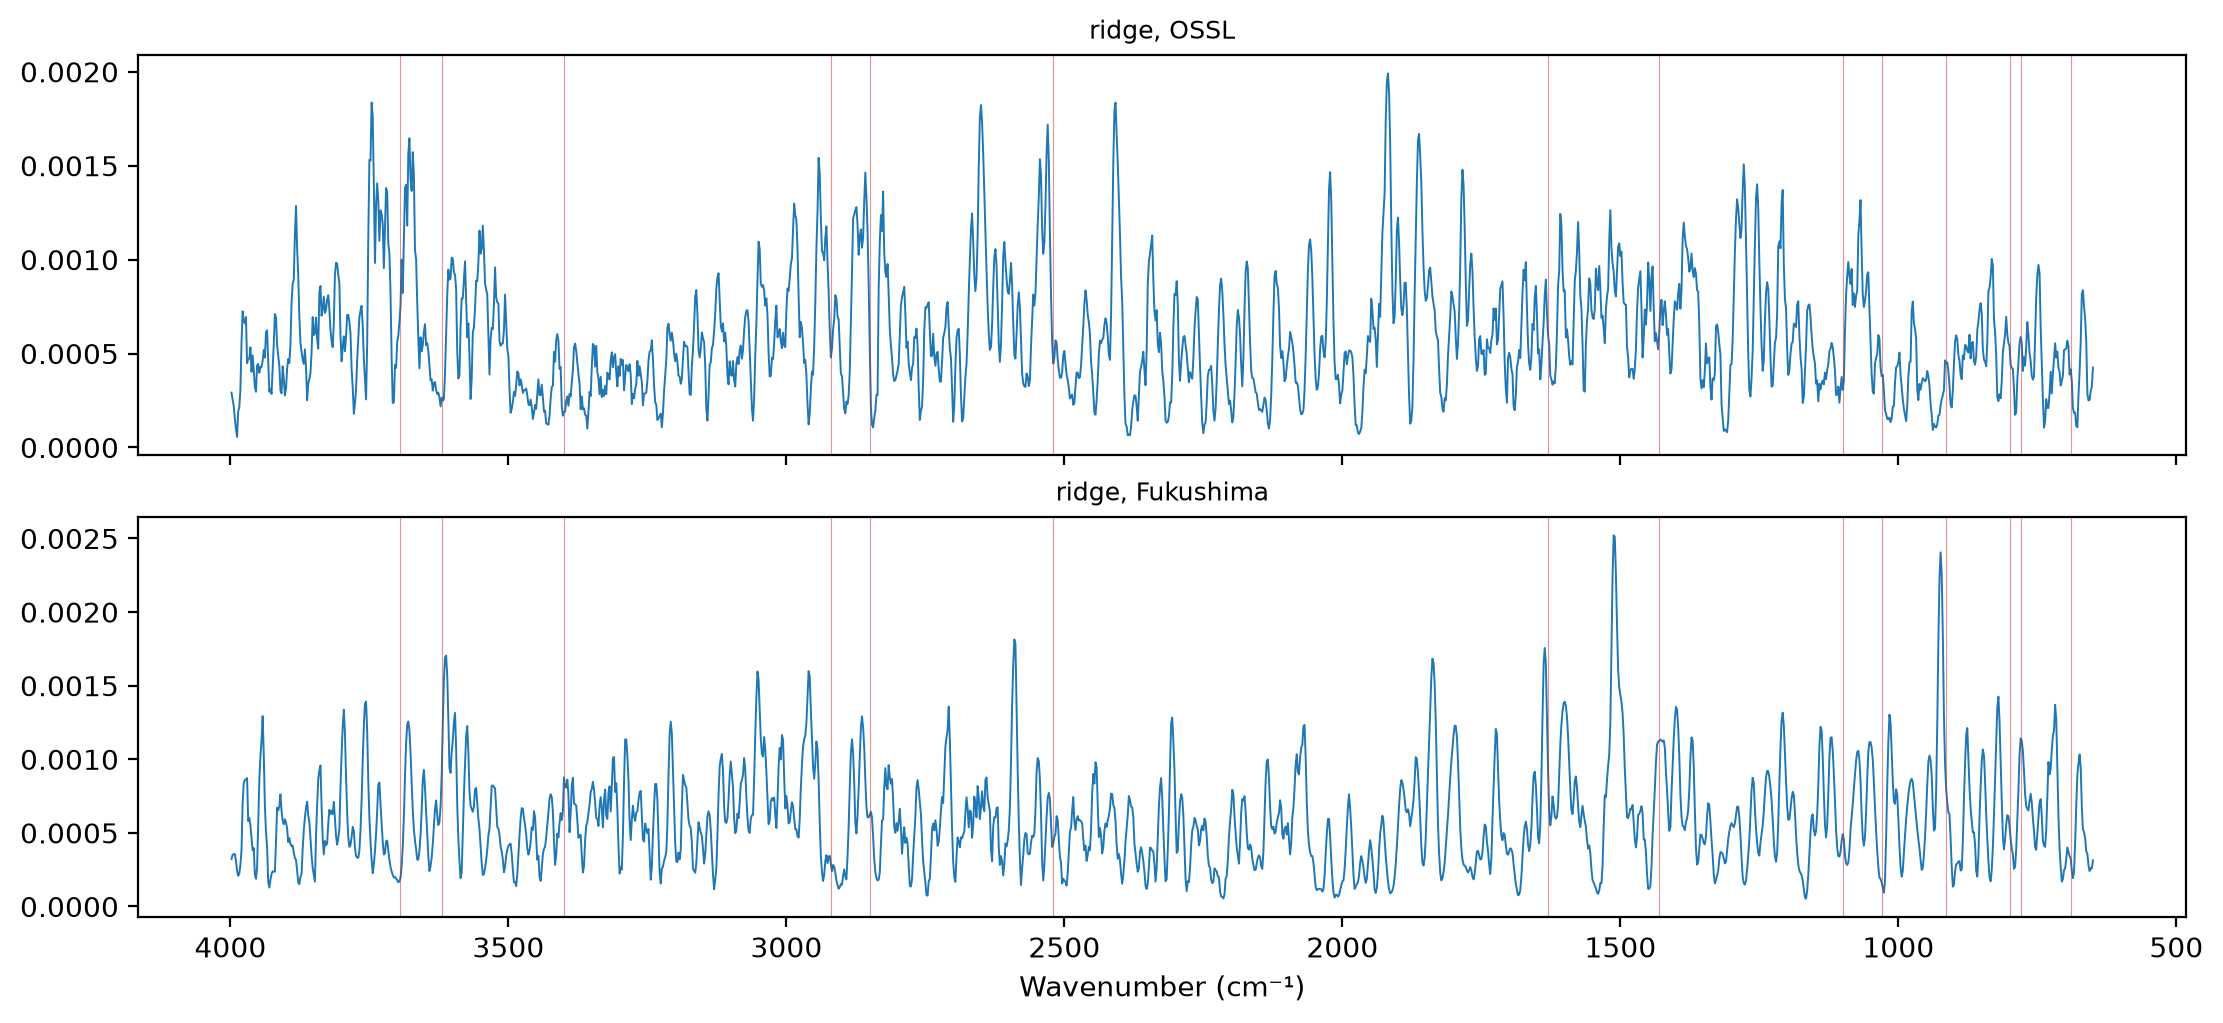

,"OSSL model, OSSL","OSSL model, Fukushima","fully fine-tuned, Fukushima","Fukushima only, Fukushima","ridge, OSSL","ridge, Fukushima"
"ridge, OSSL",0.15,0.13,0.20,0.16,1.00,0.09
"ridge, Fukushima",0.05,0.08,0.12,0.07,0.09,1.00


In [ ]:
#| fukudata
tr_o = np.random.default_rng(1).choice(np.setdiff1d(np.arange(len(Xo_d)), va), 20000, replace=False)
coef = {}
for k, (X, y) in {'ridge, OSSL': (Xo_d[tr_o], yo[tr_o]), 'ridge, Fukushima': (Xf_d[~is_test], yf[~is_test])}.items():
    c = np.abs(make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 6, 15))).fit(X, y)[-1].coef_)
    coef[k] = c / c.sum()
coef = pd.DataFrame(coef, index=shared_wns)
fig, axs = plt.subplots(2, 1, figsize=(11, 5), sharex=True, layout='constrained')
for ax, k in zip(axs, coef):
    ax.plot(shared_wns, coef[k].rolling(5, center=True, min_periods=1).mean(), lw=0.7); ax.set_title(k, fontsize=9); annotate(ax)
axs[-1].invert_xaxis(); axs[-1].set_xlabel('Wavenumber (cm⁻¹)')
pd.concat([sm, coef.rolling(5, center=True, min_periods=1).mean()], axis=1).corr().loc[list(coef), :].round(2)

## Findings

On OSSL, the OSSL Kex model relies most densely on the 3600–3700 cm⁻¹ region, the Al–OH stretching bands of illite, smectite and kaolinite near 3620 cm⁻¹. By integrated gradients, that 100 cm⁻¹ region holds 10% of the importance, more per cm⁻¹ than any other region. Flattening the 40 cm⁻¹ window centred at 3629 cm⁻¹ raises the error more than any other window. Overall, 64% of the importance lies below 2000 cm⁻¹: 38% between 650 and 1300 cm⁻¹ and 26% between 1300 and 2000 cm⁻¹. For Kex, an illite band is a plausible thing to rely on, since illite holds K. That reading is a hypothesis about the model, not a result.

On the Fukushima spectra, the same model spreads its importance differently. The share of 3600–3700 cm⁻¹ falls from 10% to 5.7%, and the share of 650–1300 cm⁻¹ from 38% to 28%. The share of 2000–3200 cm⁻¹ rises from 13% to 23%. In the occlusion test on Fukushima, the window that matters most is centred at 3749 cm⁻¹, with 3629 cm⁻¹ second. The correlation between the model's profiles on OSSL and on Fukushima is 0.66.

The models trained on Fukushima differ from the OSSL model. The fully fine-tuned model's profile on Fukushima correlates at 0.69 with the OSSL model's on OSSL. It keeps 10% of its importance in 3600–3700 cm⁻¹. The Fukushima-only model correlates at 0.48. It gives 6.8% to 3600–3700 cm⁻¹ and 18% to 2000–2800 cm⁻¹, against 6.8% for the OSSL model on OSSL. Its most important occlusion windows are centred at 3709, 2829 and 1589 cm⁻¹.

The ridge coefficients are not a usable importance measure here. The OSSL and Fukushima ridge profiles correlate at 0.09, and with the integrated-gradient profiles at 0.05 to 0.20. Neighbouring wavenumbers are strongly correlated, so ridge spreads its weight over them in ways that change from one dataset to the other.

These results connect with `16_moisture`. Between 3450 and 3700 cm⁻¹, the Thermo spectra are higher than their OSSL analogues by 0.87 after SNV, in 99% of the pairs. A broad absorption there could hide the sharp Al–OH band that the OSSL model relies on most. Measuring the 3620 cm⁻¹ band height in both datasets, and its relation to Kex in each, would test this. This notebook doesn't.

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()